# Notebook 02 — Out-of-Sample VaR & Expected Shortfall Backtesting
**Goal:** Forecast 1-day 99% and 97.5% Value-at-Risk (VaR) and Expected Shortfall (ES) using four methods (Historical, Normal, Student-$t$, and GARCH-Filtered Historical Simulation) with a rolling 1,000-day window across 2004–2025, evaluate them with Kupiec, Christoffersen, and Basel Traffic-Light tests, and replay historical crisis scenarios on our 25-stock equal-weight portfolio.

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from volrisk.universe import STOCKS, INDEX
from volrisk.data_loader import load_prices, log_returns_pct
from volrisk.var_models import (
    var_es_historical,
    var_es_normal,
    var_es_student_t,
    var_es_fhs,
)
from volrisk.backtest import rolling_forecasts, backtest_table
from volrisk.stress import scenario_replay

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
CACHE_DIR = ROOT / "data" / "processed"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

prices = load_prices()
r_idx = log_returns_pct(prices[INDEX])

# Quick check of all 4 methods on the first 1,000 trading days
w0 = r_idx.iloc[:1000].to_numpy()
print("=== 1-Day 99% VaR & ES on Initial 1,000-Day Window ===")
for name, fn in [("Historical", var_es_historical), ("Normal", var_es_normal),
                 ("Student-t", var_es_student_t), ("GARCH-FHS", var_es_fhs)]:
    v, es = fn(w0, 0.99)
    print(f"{name:12s} | VaR_99 = {v:.3f}% | ES_99 = {es:.3f}%")

=== 1-Day 99% VaR & ES on Initial 1,000-Day Window ===
Historical   | VaR_99 = 3.348% | ES_99 = 4.156%
Normal       | VaR_99 = 3.246% | ES_99 = 3.715%
Student-t    | VaR_99 = 3.553% | ES_99 = 4.499%
GARCH-FHS    | VaR_99 = 1.841% | ES_99 = 2.348%


### 1. Rolling Out-of-Sample Forecasts (2004–2025, No Look-Ahead)
For every test day $t$, we slice `r[t - 1000 : t]` (strictly excluding day $t$) and compute 1-day-ahead 99% and 97.5% VaR and ES across all four methods. Results are cached to `data/processed/rolling_var_es.parquet`.

In [6]:
cache_file = CACHE_DIR / "rolling_var_es.parquet"
if cache_file.exists():
    bt_df = pd.read_parquet(cache_file)
else:
    print("Running rolling forecasts across 2004-2025 (takes ~1-2 minutes)...")
    bt_df = rolling_forecasts(r_idx, window=1000, levels=(0.99, 0.975), refit_every=25)
    bt_df.to_parquet(cache_file)

print(f"Out-of-sample period: {bt_df.index[0].date()} to {bt_df.index[-1].date()} ({len(bt_df)} trading days)\n")

print("=== 1. Full Out-of-Sample Period (2004–2025) ===")
print(backtest_table(bt_df).to_string(index=False))

print("\n=== 2. 2008 Global Financial Crisis (2008-01-01 to 2009-06-30) ===")
print(backtest_table(bt_df.loc["2008-01-01":"2009-06-30"]).to_string(index=False))

print("\n=== 3. 2020 COVID-19 Crash (2020-01-01 to 2020-12-31) ===")
print(backtest_table(bt_df.loc["2020-01-01":"2020-12-31"]).to_string(index=False))

Out-of-sample period: 2003-12-29 to 2025-12-30 (5537 trading days)

=== 1. Full Out-of-Sample Period (2004–2025) ===
Method Level  Days  Breaches  Expected  Kupiec_p  Indep_p   CC_p  ES_Ratio Worst_Traffic_Light
  HIST 99.0%  5537        83      55.4    0.0005   0.0000 0.0000      1.07            red (27)
  HIST 97.5%  5537       155     138.4    0.1614   0.0000 0.0000      1.09                   -
  NORM 99.0%  5537       133      55.4    0.0000   0.0000 0.0000      1.39            red (37)
  NORM 97.5%  5537       195     138.4    0.0000   0.0000 0.0000      1.37                   -
     T 99.0%  5537       190      55.4    0.0000   0.0000 0.0000      1.00            red (57)
     T 97.5%  5537       350     138.4    0.0000   0.0000 0.0000      1.09                   -
   FHS 99.0%  5537        74      55.4    0.0167   0.0974 0.0144      1.00            red (11)
   FHS 97.5%  5537       145     138.4    0.5743   0.9159 0.8493      1.01                   -

=== 2. 2008 Global Financia

### 2. Visualizing 2008 & 2020 Crisis Breaches: Normal VaR vs. GARCH-FHS VaR
Static Normal VaR reacts too slowly when a crisis hits, causing breaches to cluster on back-to-back days (failing Christoffersen's independence test and entering the Basel Red Zone). GARCH-Filtered Historical Simulation immediately widens the risk threshold as $\hat{\sigma}_{t+1}$ rises.

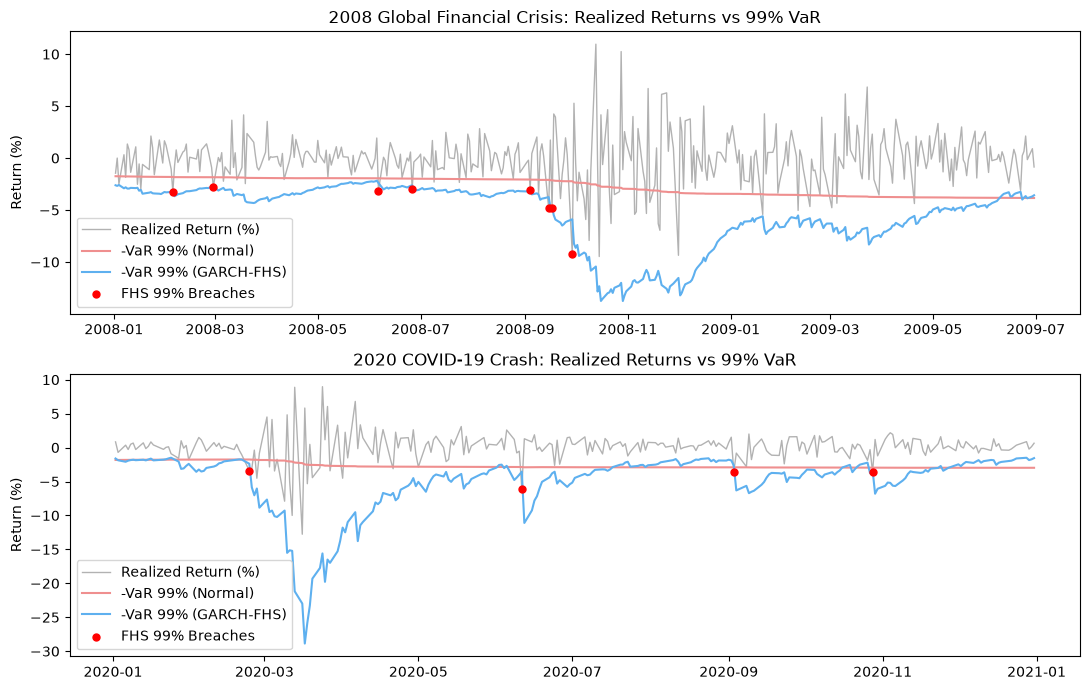

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=False)

for idx, (start, end, title) in enumerate([
    ("2008-01-01", "2009-06-30", "2008 Global Financial Crisis: Realized Returns vs 99% VaR"),
    ("2020-01-01", "2020-12-31", "2020 COVID-19 Crash: Realized Returns vs 99% VaR"),
]):
    sub = bt_df.loc[start:end]
    ax[idx].plot(sub.index, sub["realized"], color="gray", alpha=0.6, lw=1, label="Realized Return (%)")
    ax[idx].plot(sub.index, -sub["var_norm_99"], color="#ef8f8f", lw=1.5, label="-VaR 99% (Normal)")
    ax[idx].plot(sub.index, -sub["var_fhs_99"], color="#5eb0ef", lw=1.5, label="-VaR 99% (GARCH-FHS)")
    hits = sub[sub["hit_fhs_99"] == 1]
    ax[idx].scatter(hits.index, hits["realized"], color="red", s=25, zorder=5, label="FHS 99% Breaches")
    ax[idx].set_title(title)
    ax[idx].set_ylabel("Return (%)")
    ax[idx].legend(loc="lower left")

plt.tight_layout()
plt.savefig(FIG_DIR / "02_var_2008_backtest.png", dpi=150)
plt.show()

### 3. Historical Stress Scenario Replay on the 25-Stock Equal-Weight Portfolio
We construct a daily-rebalanced equal-weight portfolio from our 25 Project 1 stocks (`STOCKS`) using simple percentage returns and replay the 2008 Lehman aftermath (`2008-09-15` to `2008-10-31`) and the 2020 COVID crash (`2020-02-19` to `2020-03-23`).
*Limitation:* Because our universe selects 25 companies that survived to the present day, this replay suffers from survivorship bias.

=== Historical Stress Scenario Replay (25-Stock Equal-Weight Portfolio) ===
                  Window  Days  Cum_Return_%  Worst_Day_%  Max_Drawdown_%  Breaches_HIST_99  Breaches_NORM_99  Breaches_T_99  Breaches_FHS_99
2008-09-15 to 2008-10-31    35        -14.25        -8.88           25.87                10                13             13                3
2020-02-19 to 2020-03-23    24        -30.70       -11.27           30.94                10                12             12                1


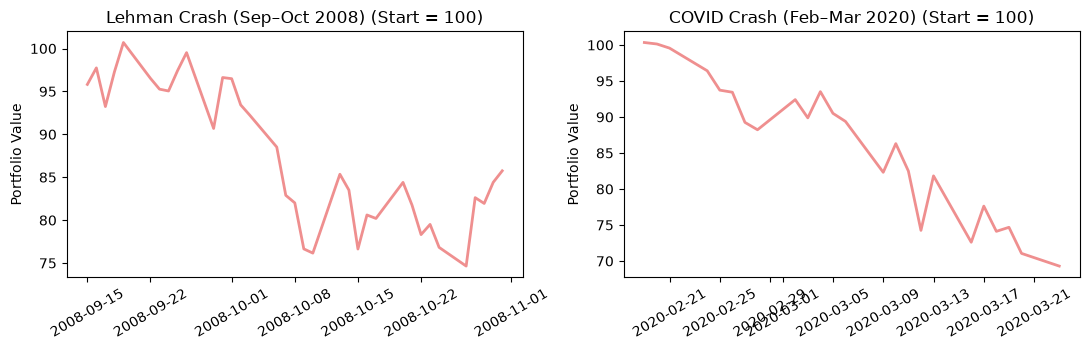

In [8]:
ew_simple_ret = (100.0 * prices[STOCKS].pct_change().dropna()).mean(axis=1)

s08 = scenario_replay(ew_simple_ret, "2008-09-15", "2008-10-31", var_df=bt_df)
s20 = scenario_replay(ew_simple_ret, "2020-02-19", "2020-03-23", var_df=bt_df)
stress_tbl = pd.DataFrame([s08, s20])
print("=== Historical Stress Scenario Replay (25-Stock Equal-Weight Portfolio) ===")
print(stress_tbl.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for i, (start, end, label) in enumerate([
    ("2008-09-15", "2008-10-31", "Lehman Crash (Sep–Oct 2008)"),
    ("2020-02-19", "2020-03-23", "COVID Crash (Feb–Mar 2020)"),
]):
    w = ew_simple_ret.loc[start:end]
    cum_wealth = 100.0 * np.cumprod(1.0 + w / 100.0)
    ax[i].plot(w.index, cum_wealth, color="#ef8f8f", lw=2)
    ax[i].set_title(f"{label} (Start = 100)")
    ax[i].set_ylabel("Portfolio Value")
    ax[i].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_stress_replay.png", dpi=150)
plt.show()